<h1>P2: EKF-Enhanced MPC for a DC Motor</h1>
<h2>Additional Tasks</h2>
  <hr>
  <p>
    Below are <strong>suggested</strong> additional tasks to obtain an excellent grade for the project. 
    Students are encouraged to come up with their own ideas for additional investigations; 
    not all suggestions below must be included for an excellent grade.
  </p>

  <ul>
    <li>
      <strong>Test the EKF and MPC under a time-varying load torque:</strong> 
      Evaluate the system using a time-varying load torque (&tau;<sub>l</sub>). 
      For example, you may model it as a sinusoidal disturbance with an offset:
      <br>
      &tau;<sub>l</sub><sup>plant</sup>(k) = &tau;<sub>offset</sub> + A sin(fk)
    </li>
    <li>
      <strong>Parameter Convergence Visualization:</strong> 
      Include a figure in your report demonstrating how the Extended Kalman Filter’s (EKF) 
      parameter estimate converges to the true value (whether that value is constant or time-varying).
    </li>
  </ul>

<h3> For Single Setpoint </h3>

Running Time-Varying Load Simulation...


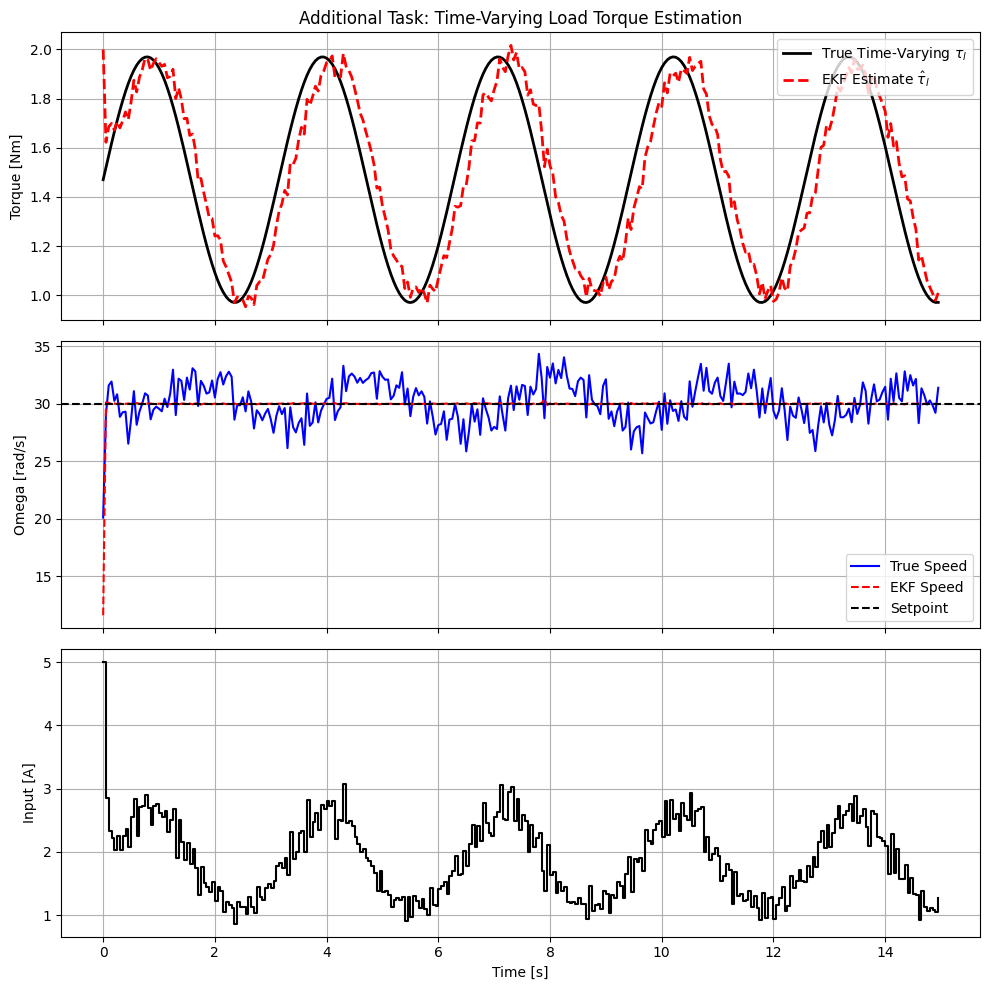

In [7]:
# ============================================================================
# Technical University of Dortmund
# Advanced Process Control WS 25/26
# P2: EKF-Enhanced MPC for a DC Motor
# ADDITIONAL TASK: Time-Varying Load Torque Estimation
# ============================================================================

from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# 1. System Parameters
# =========================
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05

# Time-Varying Load Parameters (Sinusoidal Disturbance)
tau_offset = 1.47
tau_amplitude = 0.5
tau_freq = 2.0  # rad/s

# Initial Guess for EKF (Wrong value to test convergence)
tl_initial_guess = 2.0

# Noise Statistics
var_v = 1.0       # Measurement noise
var_w1 = 0.01     # Process noise (current)
var_w2 = 100.0    # Process noise (omega)
# Parameter Process Noise (Higher value = faster tracking of changing load)
var_w_tau = 0.1   

# Dimensions
nx_mpc = 2  # [ia, omega]
nu = 1      # [u]
nx_ekf = 3  # [ia, omega, tau_l]

# MPC Settings
N = 20
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# =========================
# 2. CasADi Functions
# =========================

# --- 2.1 Augmented EKF Model (Estimates Torque) ---
x_aug = SX.sym("x_aug", nx_ekf) # [ia, omega, tau_l]
u_sym = SX.sym("u", nu)

# Dynamics: d(tau)/dt = 0 (Random Walk assumption allows tracking)
xdot_aug = vertcat(
    -(Ra/La)*x_aug[0] - (km/La)*x_aug[1]*u_sym[0] + (ua/La),
    -(B/J)*x_aug[1] + (km/J)*x_aug[0]*u_sym[0] - (x_aug[2]/J), # Use estimated torque
    0 
)
f_aug_step = Function('f_aug', [x_aug, u_sym], [xdot_aug])

# Discretize EKF Model
k1 = f_aug_step(x_aug, u_sym)
k2 = f_aug_step(x_aug + dt/2*k1, u_sym)
k3 = f_aug_step(x_aug + dt/2*k2, u_sym)
k4 = f_aug_step(x_aug + dt*k3, u_sym)
x_next_aug = x_aug + (dt/6)*(k1 + 2*k2 + 2*k3 + k4)

# Jacobians for EKF
A_fun = Function('A_fun', [x_aug, u_sym], [jacobian(x_next_aug, x_aug)])
C_fun = Function('C_fun', [x_aug], [jacobian(x_aug[1], x_aug)]) # Measure Omega
f_aug_disc = Function('f_aug_disc', [x_aug, u_sym], [x_next_aug])

# --- 2.2 MPC Model (Adaptive) ---
x_mpc = SX.sym("x_mpc", nx_mpc)
tl_param = SX.sym("tl_param") # Torque provided by EKF

xdot_mpc = vertcat(
    -(Ra/La)*x_mpc[0] - (km/La)*x_mpc[1]*u_sym[0] + (ua/La),
    -(B/J)*x_mpc[1] + (km/J)*x_mpc[0]*u_sym[0] - (tl_param/J)
)
f_mpc_cont = Function('f_mpc', [x_mpc, u_sym, tl_param], [xdot_mpc])

# --- 2.3 True Plant (Time-Varying) ---
# We handle the time-varying torque inside the simulation loop manually
x_plant = SX.sym("x_p", nx_mpc)
tau_true_input = SX.sym("tau_true") 

xdot_plant = vertcat(
    -(Ra/La)*x_plant[0] - (km/La)*x_plant[1]*u_sym[0] + (ua/La),
    -(B/J)*x_plant[1] + (km/J)*x_plant[0]*u_sym[0] - (tau_true_input/J)
)
plant_integrator = integrator('F', 'idas', {'x': x_plant, 'p': vertcat(u_sym, tau_true_input), 'ode': xdot_plant}, {'tf': dt})

# =========================
# 3. Solver Setup (MPC)
# =========================
# Standard Orthogonal Collocation
tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")
def L(j):
    lj = 1
    for r in range(K1):
        if r != j: lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj
A_coll = np.zeros((K1, K1)); D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj  = Function(f"Lj{j}",  [tau], [L(j)])
    for k in range(K1): A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

opt = struct_symSX([entry("x", shape=(nx_mpc,), repeat=[N+1, K1]), entry("u", shape=(nu,), repeat=[N])])
w_opt = opt.cat
p_opts = vertcat(SX.sym("x0", nx_mpc), SX.sym("w_sp"), SX.sym("tau_est"))

Jcost = 0; g = []; lbg = []; ubg = []
g.append(opt["x",0,0] - p_opts[0:2]); lbg+=[0]*nx_mpc; ubg+=[0]*nx_mpc

for i in range(N):
    st = opt["x", i, 0]; ui = opt["u", i]
    Jcost += 50*(st[1]-p_opts[2])**2 + 0.1*st[0]**2 + 0.01*ui[0]**2 # Track Setpoint
    
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_mpc_cont(x_ik, ui, p_opts[3]) # Use ESTIMATED torque
        gk = 0
        for j in range(K1): gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt*fk); lbg+=[0]*nx_mpc; ubg+=[0]*nx_mpc
        
    x_end = 0
    for j in range(K1): x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i+1, 0] - x_end); lbg+=[0]*nx_mpc; ubg+=[0]*nx_mpc

Jcost += 50*(opt["x", N, 0][1] - p_opts[2])**2
g = vertcat(*g)

# Bounds
lbw = opt(0); ubw = opt(0)
for i in range(N+1):
    for j in range(K1): lbw["x", i, j] = [ia_min, w_min]; ubw["x", i, j] = [ia_max, w_max]
for i in range(N): lbw["u", i] = [u_min]; ubw["u", i] = [u_max]

solver = nlpsol('solver', 'ipopt', {'x': w_opt, 'f': Jcost, 'g': g, 'p': p_opts}, {'ipopt.print_level':0, 'print_time':0})

# =========================
# 4. Simulation Loop
# =========================
def run_time_varying_sim():
    print("Running Time-Varying Load Simulation...")
    steps = 300
    time = np.arange(steps) * dt
    
    # Generate True Load Profile
    tau_true_profile = tau_offset + tau_amplitude * np.sin(tau_freq * time)
    
    x_true = np.zeros((nx_mpc, 1))
    x_est = np.array([0.0, 0.0, tl_initial_guess]).reshape(nx_ekf, 1)
    P_est = np.diag([1.0, 100.0, 1.0])
    Q_ekf = np.diag([var_w1, var_w2, var_w_tau])
    R_ekf = np.array([[var_v]])
    
    hist_x = []; hist_est = []; hist_tau_true = []; hist_u = []
    opt_sol = None
    wsp = 30.0
    
    u_last = np.zeros((1,1))
    
    for k in range(steps):
        # 1. Current True Torque
        curr_tau = tau_true_profile[k]
        
        # 2. Measurement
        y_meas = x_true[1] + np.random.normal(0, np.sqrt(var_v))
        
        # 3. EKF Update
        if k > 0:
            res = y_meas - x_est[1]
            Ck = C_fun(x_est).full()
            Sk = Ck @ P_est @ Ck.T + R_ekf
            Kk = P_est @ Ck.T @ np.linalg.inv(Sk)
            x_est = x_est + Kk * res
            P_est = (np.eye(nx_ekf) - Kk @ Ck) @ P_est
            
        # 4. MPC (Use Estimated Torque)
        est_tau = x_est[2]
        est_state = x_est[0:2]
        
        # Warm start guess logic (simplified)
        w0 = opt(0) 
        if opt_sol: w0 = opt_sol # Reuse previous solution if available
        
        try:
            sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=vertcat(est_state, wsp, est_tau))
            opt_sol = opt(sol['x']) # Save for warm start
            u_k = opt_sol['u', 0].full()
        except:
            u_k = u_last # Safety fallback
            
        u_last = u_k
        
        # 5. Plant Step (With TRUE Time-Varying Torque)
        res_int = plant_integrator(x0=x_true, p=vertcat(u_k, curr_tau))
        x_true_next = res_int['xf'].full()
        
        # Process Noise
        w_noise = np.array([np.random.normal(0, np.sqrt(var_w1)), np.random.normal(0, np.sqrt(var_w2))]).reshape(2,1)
        x_true = x_true_next + w_noise * dt
        
        # 6. EKF Predict
        x_est_next = f_aug_disc(x_est, u_k).full()
        Ak = A_fun(x_est, u_k).full()
        P_est = Ak @ P_est @ Ak.T + Q_ekf
        x_est = x_est_next
        
        # Log
        hist_x.append(x_true.flatten())
        hist_est.append(x_est.flatten())
        hist_tau_true.append(curr_tau)
        hist_u.append(u_k.flatten())
        
    return np.array(hist_x), np.array(hist_est), np.array(hist_tau_true), np.array(hist_u), time

# =========================
# 5. Plotting Results
# =========================
if __name__ == "__main__":
    X, Est, Tau_True, U, t = run_time_varying_sim()
    
    fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    
    # 1. Parameter Estimation (The Goal of the Task)
    ax[0].set_title("Additional Task: Time-Varying Load Torque Estimation")
    ax[0].plot(t, Tau_True, 'k-', linewidth=2, label='True Time-Varying $\\tau_l$')
    ax[0].plot(t, Est[:, 2], 'r--', linewidth=2, label='EKF Estimate $\\hat{\\tau}_l$')
    ax[0].set_ylabel('Torque [Nm]')
    ax[0].legend(loc='upper right')
    ax[0].grid(True)
    
    # 2. Tracking Performance
    ax[1].plot(t, X[:, 1], 'b-', label='True Speed')
    ax[1].plot(t, Est[:, 1], 'r--', label='EKF Speed')
    ax[1].axhline(30, color='k', linestyle='--', label='Setpoint')
    ax[1].set_ylabel('Omega [rad/s]')
    ax[1].legend(loc='lower right')
    ax[1].grid(True)
    
    # 3. Input
    ax[2].step(t, U, 'k-', where='post')
    ax[2].set_ylabel('Input [A]')
    ax[2].set_xlabel('Time [s]')
    ax[2].grid(True)
    
    plt.tight_layout()
    plt.savefig("additional_task_varying_load.png")
    plt.show()

<h3> For Multiple Setpoints </h3>

ADDITIONAL TASK: Time-Varying Parameter Estimation
τ_l(k) = 1.47 + 0.5·sin(0.05·k) Nm
Initial guess: 2.0 Nm
Mean parameter error: 0.1525 Nm
Final parameter error: 0.0695 Nm
RMSE (tracking): 15.1609 rad/s


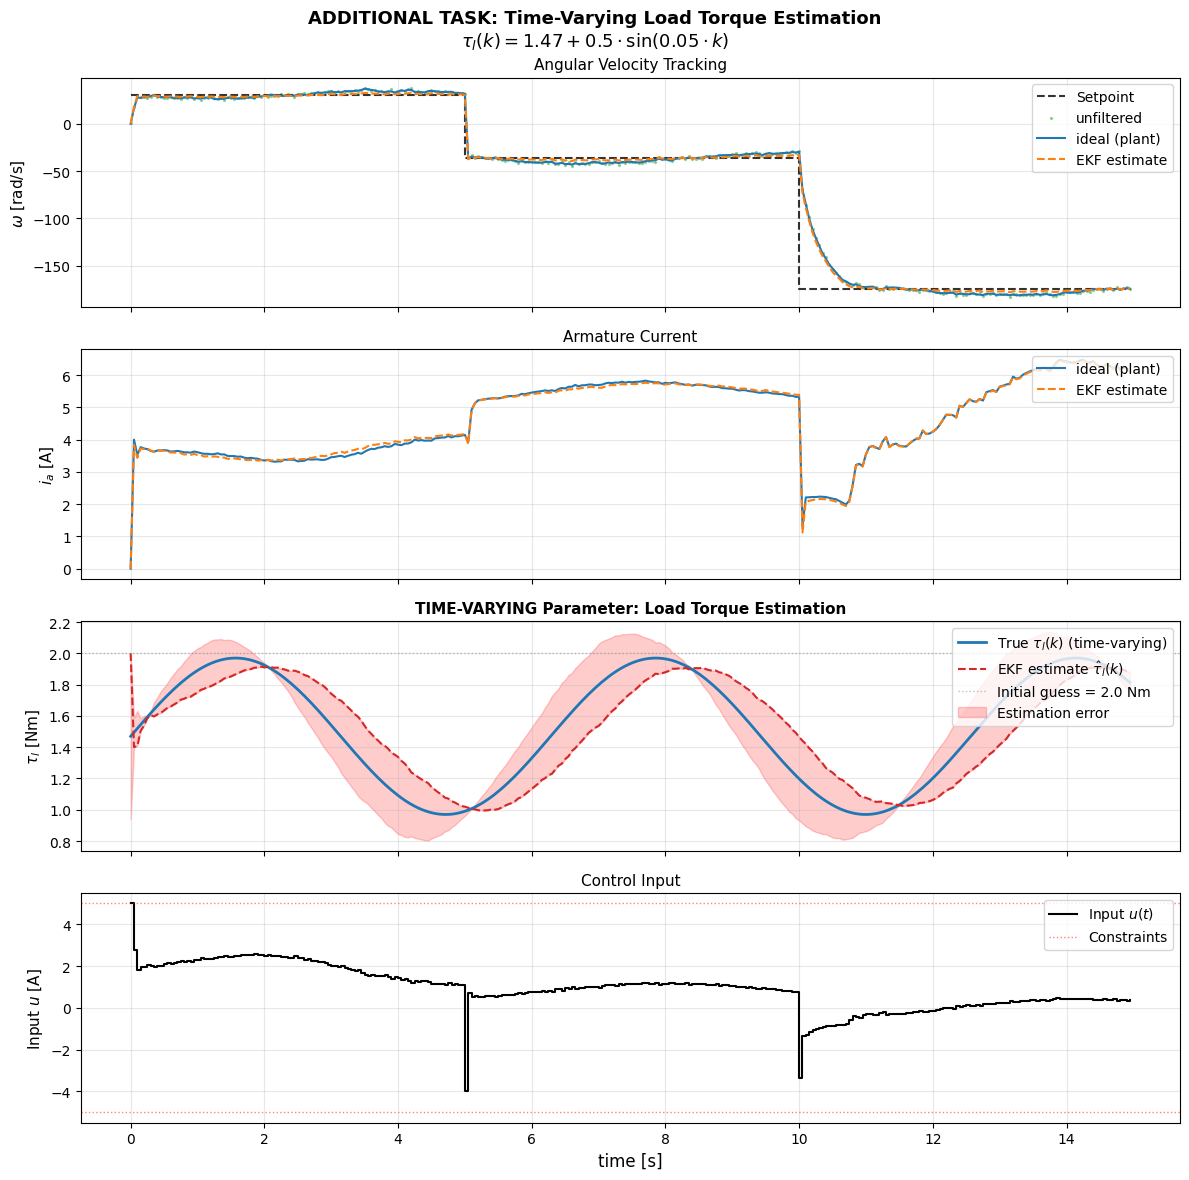

In [9]:
from casadi import *
from casadi.tools import *
import numpy as np
import matplotlib.pyplot as plt

# =========================
# System Parameters
# =========================
Ra = 12.345
La = 0.314
km = 0.253
J = 0.00441
B = 0.00732
ua = 60.0
dt = 0.05

# Time-varying load torque parameters
tau_offset = 1.47
A_amplitude = 0.5
f_frequency = 0.05

tl_model_init = 2.0

# Noise statistics
var_v = 1.0
var_w1 = 0.01
var_w2 = 100.0
var_w3 = 0.01

Q_ekf = np.diag([var_w1 * dt**2, var_w2 * dt**2, var_w3 * dt**2])
R_ekf = np.array([[var_v]])

# Dimensions
nx_orig = 2
nx = 3
nu = 1
ny = 1

# MPC settings
N = 30
K = 2
K1 = K + 1

# Constraints
u_min, u_max = -5.0, 5.0
ia_min, ia_max = -10.0, 10.0
w_min, w_max = -200.0, 35.0

# Cost weights
Qw, Qi, Ru = 5.0, 0.5, 20.0

# =========================
# Time-Varying Load Torque
# =========================

def tau_l_timevarying(k):
    return tau_offset + A_amplitude * np.sin(f_frequency * k)

# =========================
# Plant Model (time-varying torque)
# =========================

x_plant = SX.sym("x_plant", nx_orig)
u_plant = SX.sym("u_plant", nu)
tl_plant_sym = SX.sym("tl_plant")

ia_plant, om_plant = x_plant[0], x_plant[1]

xdot_plant = vertcat(
    -(Ra / La) * ia_plant - (km / La) * om_plant * u_plant[0] + (ua / La),
    -(B / J) * om_plant + (km / J) * ia_plant * u_plant[0] - (tl_plant_sym / J)
)
f_cont_plant = Function('f_cont_plant', [x_plant, u_plant, tl_plant_sym], [xdot_plant])

# RK4 discretization
k1_p = f_cont_plant(x_plant, u_plant, tl_plant_sym)
k2_p = f_cont_plant(x_plant + dt/2 * k1_p, u_plant, tl_plant_sym)
k3_p = f_cont_plant(x_plant + dt/2 * k2_p, u_plant, tl_plant_sym)
k4_p = f_cont_plant(x_plant + dt * k3_p, u_plant, tl_plant_sym)
x_next_plant = x_plant + (dt/6) * (k1_p + 2*k2_p + 2*k3_p + k4_p)
plant_integrator = Function('F_plant', [x_plant, u_plant, tl_plant_sym], [x_next_plant])

# =========================
# Augmented EKF Model
# =========================

x_aug = SX.sym("x_aug", nx)
u_model = SX.sym("u_model", nu)
ia_model, om_model, tl_est = x_aug[0], x_aug[1], x_aug[2]

xdot_aug = vertcat(
    -(Ra / La) * ia_model - (km / La) * om_model * u_model[0] + (ua / La),
    -(B / J) * om_model + (km / J) * ia_model * u_model[0] - (tl_est / J),
    0.0
)
f_cont_aug = Function('f_cont_aug', [x_aug, u_model], [xdot_aug])

# RK4 discretization
k1 = f_cont_aug(x_aug, u_model)
k2 = f_cont_aug(x_aug + dt / 2 * k1, u_model)
k3 = f_cont_aug(x_aug + dt / 2 * k2, u_model)
k4 = f_cont_aug(x_aug + dt * k3, u_model)
x_next_aug = x_aug + (dt / 6) * (k1 + 2 * k2 + 2 * k3 + k4)
f_disc_aug = Function('f_disc_aug', [x_aug, u_model], [x_next_aug])

# Jacobians
A_aug = jacobian(x_next_aug, x_aug)
C_aug = jacobian(x_aug[1], x_aug)

A_aug_fun = Function('A_aug_fun', [x_aug, u_model], [A_aug])
C_aug_fun = Function('C_aug_fun', [x_aug], [C_aug])

P_0 = np.diag([1.0, 100.0, 2.0])

def ekf_predict(x_hat, u_k, P):
    x_pred = f_disc_aug(x_hat, u_k).full()
    A_k = A_aug_fun(x_hat, u_k).full()
    P_pred = A_k @ P @ A_k.T + Q_ekf
    return x_pred, P_pred

def ekf_update(x_pred, P_pred, y_meas):
    C_k = C_aug_fun(x_pred).full()
    y_pred = x_pred[1]
    y_meas = y_meas.reshape(-1, 1)
    y_pred = y_pred.reshape(-1, 1)
    innovation = y_meas - y_pred
    S = C_k @ P_pred @ C_k.T + R_ekf
    K_gain = P_pred @ C_k.T @ np.linalg.inv(S)
    x_new = x_pred + K_gain @ innovation
    P_new = (np.eye(nx) - K_gain @ C_k) @ P_pred
    P_new = (P_new + P_new.T) / 2
    return x_new, P_new

# =========================
# MPC Setup
# =========================

tau_col = [0.0] + collocation_points(K, "radau")
tau = SX.sym("tau")

def L(j):
    lj = 1
    for r in range(K1):
        if r != j: 
            lj *= (tau - tau_col[r]) / (tau_col[j] - tau_col[r])
    return lj

A_coll = np.zeros((K1, K1))
D_coll = np.zeros((K1, 1))
for j in range(K1):
    dLj = Function(f"dLj{j}", [tau], [jacobian(L(j), tau)])
    Lj = Function(f"Lj{j}", [tau], [L(j)])
    for k in range(K1): 
        A_coll[j, k] = float(dLj(tau_col[k]))
    D_coll[j] = float(Lj(1.0))

opt = struct_symSX([
    entry("x", shape=(nx_orig,), repeat=[N + 1, K1]),
    entry("u", shape=(nu,), repeat=[N])
])

w_opt = opt.cat
x_init = SX.sym("x_init", nx_orig)
tl_param = SX.sym("tl_param")
w_sp = SX.sym("w_sp")
p = vertcat(x_init, tl_param, w_sp)

Jcost = 0
g, lbg, ubg = [], [], []

g.append(opt["x", 0, 0] - x_init)
lbg += [0.0] * nx_orig
ubg += [0.0] * nx_orig

x_mpc = SX.sym("x_mpc", nx_orig)
u_mpc = SX.sym("u_mpc", nu)
tl_mpc = SX.sym("tl_mpc")
ia_mpc, om_mpc = x_mpc[0], x_mpc[1]

xdot_mpc = vertcat(
    -(Ra / La) * ia_mpc - (km / La) * om_mpc * u_mpc[0] + (ua / La),
    -(B / J) * om_mpc + (km / J) * ia_mpc * u_mpc[0] - (tl_mpc / J)
)
f_cont_mpc = Function('f_cont_mpc', [x_mpc, u_mpc, tl_mpc], [xdot_mpc])

for i in range(N):
    st = opt["x", i, 0]
    ui = opt["u", i]
    Jcost += Qw * (st[1] - w_sp) ** 2 + Qi * (st[0]) ** 2 + Ru * (ui[0]) ** 2
    
    for k in range(1, K1):
        x_ik = opt["x", i, k]
        fk = f_cont_mpc(x_ik, ui, tl_param)
        gk = 0
        for j in range(K1): 
            gk += A_coll[j, k] * opt["x", i, j]
        g.append(gk - dt * fk)
        lbg += [0.0] * nx_orig
        ubg += [0.0] * nx_orig
    
    x_end = 0
    for j in range(K1): 
        x_end += D_coll[j] * opt["x", i, j]
    g.append(opt["x", i + 1, 0] - x_end)
    lbg += [0.0] * nx_orig
    ubg += [0.0] * nx_orig

Jcost += Qw * (opt["x", N, 0][1] - w_sp) ** 2 + Qi * (opt["x", N, 0][0]) ** 2
g = vertcat(*g)

lbw = opt(0)
ubw = opt(0)
for i in range(N + 1):
    for j in range(K1):
        lbw["x", i, j] = [ia_min, w_min]
        ubw["x", i, j] = [ia_max, w_max]
for i in range(N):
    lbw["u", i] = [u_min]
    ubw["u", i] = [u_max]

nlp = {"x": w_opt, "f": Jcost, "g": g, "p": p}
opts = {
    "ipopt.print_level": 0, 
    "print_time": 0, 
    "ipopt.tol": 1e-4, 
    "ipopt.warm_start_init_point": "yes"
}
solver = nlpsol("solver", "ipopt", nlp, opts)

def make_guess(xk, prev_sol=None):
    w0 = opt(0)
    if prev_sol is None:
        for i in range(N + 1):
            for j in range(K1): 
                w0["x", i, j] = xk
    else:
        last_x, last_u = prev_sol["x"], prev_sol["u"]
        for i in range(N): 
            w0["x", i] = last_x[i + 1]
        w0["x", N] = last_x[N]
        for i in range(N - 1): 
            w0["u", i] = last_u[i + 1]
        w0["u", N - 1] = last_u[N - 1]
    return w0

# =========================
# Simulation
# =========================

def run_simulation_timevarying(setpoint_schedule, steps=300):
    
    np.random.seed(42)
    
    x_true = np.zeros((nx_orig, 1))
    x_est = np.zeros((nx, 1))
    x_est[2, 0] = tl_model_init
    P_est = P_0.copy()
    
    opt_sol = None
    
    hist_x_true = []
    hist_x_est = []
    hist_tl_true = []
    hist_tl_est = []
    hist_y_meas = []
    hist_u = []
    hist_wsp = []
    
    sp_times = []
    sp_values = []
    cumulative_time = 0
    for sp_val, duration in setpoint_schedule:
        sp_times.append(cumulative_time)
        sp_values.append(sp_val)
        cumulative_time += duration
    
    for k in range(steps):
        wsp = sp_values[0]
        for i in range(len(sp_times)):
            if k >= sp_times[i]:
                wsp = sp_values[i]
        
        tl_true_k = tau_l_timevarying(k)
        
        v_noise = np.random.normal(0, np.sqrt(var_v))
        y_meas = x_true[1] + v_noise
        y_meas = y_meas.reshape(-1, 1)
        
        if k == 0:
            x_est[0:2] = x_true.copy()
            x_est[2, 0] = tl_model_init
            P_est = P_0.copy()
        else:
            x_est, P_est = ekf_update(x_pred_a_priori, P_pred_a_priori, y_meas)
        
        x_est_phys = x_est[0:2]
        tl_est_current = float(x_est[2, 0])
        
        w0 = make_guess(x_est_phys, opt_sol)
        pk = vertcat(x_est_phys, tl_est_current, wsp)
        
        sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=pk)
        
        if solver.stats()['success']:
            opt_sol = opt(sol["x"])
            u_k = opt_sol["u", 0].full()
        else:
            u_k = hist_u[-1] if hist_u else np.zeros((nu, 1))
        
        hist_x_true.append(x_true.flatten())
        hist_x_est.append(x_est[0:2].flatten())
        hist_tl_true.append(tl_true_k)
        hist_tl_est.append(tl_est_current)
        hist_y_meas.append(y_meas.flatten())
        hist_u.append(u_k.flatten())
        hist_wsp.append(wsp)
        
        x_true_next = plant_integrator(x_true, u_k, tl_true_k).full()
        
        w_noise = np.array([
            np.random.normal(0, np.sqrt(var_w1)),
            np.random.normal(0, np.sqrt(var_w2))
        ]).reshape(nx_orig, 1)
        
        x_true = x_true_next + (w_noise * dt)
        
        x_pred_a_priori, P_pred_a_priori = ekf_predict(x_est, u_k, P_est)
    
    return (
        np.array(hist_x_true), 
        np.array(hist_x_est), 
        np.array(hist_tl_true),
        np.array(hist_tl_est),
        np.array(hist_y_meas), 
        np.array(hist_u), 
        np.array(hist_wsp)
    )

# =========================
# Main Execution
# =========================

if __name__ == "__main__":
    
    setpoint_schedule = [
        (30, 100),
        (-36, 100),
        (-175, 100)
    ]
    
    Xt, Xe, Tl_true, Tl_est, Ym, U, W = run_simulation_timevarying(
        setpoint_schedule, steps=300
    )
    
    t = np.arange(len(U)) * dt
    
    tracking_error = Xt[:, 1] - W
    rmse = np.sqrt(np.mean(tracking_error**2))
    
    param_error = np.abs(Tl_est - Tl_true)
    mean_param_error = np.mean(param_error)
    final_param_error = param_error[-1]
    
    print("="*70)
    print("ADDITIONAL TASK: Time-Varying Parameter Estimation")
    print("="*70)
    print(f"τ_l(k) = {tau_offset} + {A_amplitude}·sin({f_frequency}·k) Nm")
    print(f"Initial guess: {tl_model_init} Nm")
    print(f"Mean parameter error: {mean_param_error:.4f} Nm")
    print(f"Final parameter error: {final_param_error:.4f} Nm")
    print(f"RMSE (tracking): {rmse:.4f} rad/s")
    print("="*70)
    
    fig, ax = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
    
    fig.suptitle(
        f"ADDITIONAL TASK: Time-Varying Load Torque Estimation\n"
        f"$\\tau_l(k) = {tau_offset} + {A_amplitude} \\cdot \\sin({f_frequency} \\cdot k)$",
        fontsize=13, fontweight='bold'
    )
    
    ax[0].step(t, W, 'k--', linewidth=1.5, label='Setpoint', where='post', alpha=0.8)
    ax[0].scatter(t, Ym, c='tab:green', s=8, alpha=0.4, label='unfiltered', marker='.')
    ax[0].plot(t, Xt[:, 1], color='tab:blue', linewidth=1.5, label='ideal (plant)')
    ax[0].plot(t, Xe[:, 1], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF estimate')
    ax[0].set_ylabel('$\omega$ [rad/s]', fontsize=11)
    ax[0].legend(loc='upper right', fontsize=10)
    ax[0].grid(True, alpha=0.3)
    ax[0].set_title('Angular Velocity Tracking', fontsize=11)
    
    ax[1].plot(t, Xt[:, 0], color='tab:blue', linewidth=1.5, label='ideal (plant)')
    ax[1].plot(t, Xe[:, 0], color='tab:orange', linestyle='--', linewidth=1.5, label='EKF estimate')
    ax[1].set_ylabel('$i_a$ [A]', fontsize=11)
    ax[1].legend(loc='upper right', fontsize=10)
    ax[1].grid(True, alpha=0.3)
    ax[1].set_title('Armature Current', fontsize=11)
    
    ax[2].plot(t, Tl_true, color='tab:blue', linewidth=2, 
               label=f'True $\\tau_l(k)$ (time-varying)', linestyle='-')
    ax[2].plot(t, Tl_est, color='tab:red', linewidth=1.5, 
               label='EKF estimate $\\hat{\\tau}_l(k)$', linestyle='--')
    ax[2].axhline(tl_model_init, color='gray', linewidth=1, 
                  linestyle=':', label=f'Initial guess = {tl_model_init} Nm', alpha=0.5)
    ax[2].fill_between(t, Tl_true - param_error, Tl_true + param_error, 
                        color='red', alpha=0.2, label='Estimation error')
    ax[2].set_ylabel('$\\tau_l$ [Nm]', fontsize=11)
    ax[2].legend(loc='upper right', fontsize=10)
    ax[2].grid(True, alpha=0.3)
    ax[2].set_title('TIME-VARYING Parameter: Load Torque Estimation', fontsize=11, fontweight='bold')
    
    ax[3].step(t, U, 'k-', where='post', linewidth=1.5, label='Input $u(t)$')
    ax[3].axhline(u_min, color='r', linestyle=':', linewidth=1, alpha=0.5, label='Constraints')
    ax[3].axhline(u_max, color='r', linestyle=':', linewidth=1, alpha=0.5)
    ax[3].set_ylabel('Input $u$ [A]', fontsize=11)
    ax[3].set_xlabel('time [s]', fontsize=12)
    ax[3].legend(loc='upper right', fontsize=10)
    ax[3].grid(True, alpha=0.3)
    ax[3].set_title('Control Input', fontsize=11)
    
    plt.tight_layout()
    plt.savefig('additional_task_timevarying_torque.png', dpi=150, bbox_inches='tight')
    plt.show()